# PROJET N5 : Apprentissage automatique appliqué au marketing bancaire

## Objectifs

Dans ce TP, on va :

1. dire de quel type d'apprentissage il s'agit ;
2. charger les données et les explorer avec des graphiques ;
3. préparer les données (variables texte, mise à l'échelle, variable à retirer) ;
4. entraîner plusieurs modèles et les comparer ;
5. évaluer le meilleur modèle avec les bons indicateurs ;
6. interpréter les résultats pour mieux cibler une campagne.

## 1. Type d'apprentissage

**Le problème :** une banque portugaise appelle ses clients pour leur proposer un **dépôt à terme**. À partir des informations sur le client et sur la campagne, on veut prédire si le client va **souscrire (oui)** ou **ne pas souscrire (non)**.

C'est de l'**apprentissage supervisé** : pour chaque client, on connaît déjà la réponse (il a souscrit ou non). Le modèle apprend à partir de ces exemples.

C'est une **classification binaire** : la réponse n'a que deux valeurs possibles (oui ou non).

- Si on voulait prédire un nombre (par exemple le montant placé), ce serait une **régression**.
- Si on n'avait pas la réponse et qu'on cherchait juste des groupes de clients, ce serait de l'**apprentissage non supervisé**.

**L'intérêt pour la banque :** appeler tous les clients coûte cher. Un bon modèle permet d'appeler en priorité ceux qui ont le plus de chances de souscrire.

## 2. Le jeu de données

Le jeu de données **Bank Marketing** (Moro, Cortez et Rita, 2014, UCI) contient **41 188 clients** contactés entre mai 2008 et novembre 2010, avec **20 variables** et la réponse `y`.

| Variable | Type | Description |
|---|---|---|
| **Client** | | |
| age | nombre | Âge |
| job | texte | Profession |
| marital | texte | Situation familiale |
| education | texte | Niveau d'études |
| default | texte | A déjà fait défaut sur un crédit ? |
| housing | texte | A un crédit immobilier ? |
| loan | texte | A un crédit personnel ? |
| **Dernier appel** | | |
| contact | texte | Type de téléphone (portable ou fixe) |
| month | texte | Mois du dernier appel |
| day_of_week | texte | Jour du dernier appel |
| duration | nombre | Durée de l'appel en secondes (**à retirer**, voir plus loin) |
| **Historique** | | |
| campaign | nombre | Nombre d'appels pendant cette campagne |
| pdays | nombre | Jours depuis le dernier contact d'une campagne précédente (999 = jamais contacté) |
| previous | nombre | Nombre de contacts avant cette campagne |
| poutcome | texte | Résultat de la campagne précédente |
| **Contexte économique** | | |
| emp.var.rate | nombre | Taux de variation de l'emploi |
| cons.price.idx | nombre | Indice des prix à la consommation |
| cons.conf.idx | nombre | Indice de confiance des consommateurs |
| euribor3m | nombre | Taux Euribor à 3 mois |
| nr.employed | nombre | Nombre de salariés (en milliers) |
| **y** | **réponse (cible)** | **A souscrit un dépôt à terme ? (yes / no)** |

Le fichier `bank-additional-full.csv` (dans le dossier `bank-additional` du zip) doit être dans le même dossier que le notebook. Les colonnes sont séparées par des `;`, et les valeurs inconnues sont notées `unknown`.

In [ ]:
# Importation des bibliothèques
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, learning_curve, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, roc_auc_score, confusion_matrix,
                             classification_report, RocCurveDisplay)

# Reproductibilité et style des graphiques
np.random.seed(42)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Chargement du jeu de données (séparateur ;)
df = pd.read_csv("/content/drive/MyDrive/Projet de science des données N 5  Fin2/bank-additional/bank-additional/bank-additional-full.csv", sep=";")

# Réponse lisible pour les graphiques
df["souscription"] = df["y"].map({"yes": "Oui", "no": "Non"})

print("Dimensions :", df.shape)
df.head()

Dimensions : (41188, 22)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,souscription
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Non
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Non
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Non
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Non
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Non


## 3. Première exploration

On regarde les types de colonnes, les valeurs manquantes, les doublons et quelques statistiques.

In [ ]:
# Types des colonnes, valeurs manquantes et doublons
df.info()
print("\nValeurs manquantes (NaN) :", df.isna().sum().sum())
print("Lignes en double :", df.duplicated().sum())

# Les valeurs inconnues sont notées "unknown"
print("\nNombre de 'unknown' par colonne :")
print((df == "unknown").sum()[lambda s: s > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [ ]:
# Statistiques descriptives des variables numériques
variables_num = ["age", "campaign", "pdays", "previous", "emp.var.rate",
                 "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
variables_cat = ["job", "marital", "education", "default", "housing", "loan",
                 "contact", "month", "day_of_week", "poutcome"]
df[variables_num + ["duration"]].describe().round(2)

,age,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,duration
count,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00
mean,40.02,2.57,962.48,0.17,0.08,93.58,-40.50,3.62,5167.04,258.29
std,10.42,2.77,186.91,0.49,1.57,0.58,4.63,1.73,72.25,259.28
min,17.00,1.00,0.00,0.00,-3.40,92.20,-50.80,0.63,4963.60,0.00
25%,32.00,1.00,999.00,0.00,-1.80,93.08,-42.70,1.34,5099.10,102.00
50%,38.00,2.00,999.00,0.00,1.10,93.75,-41.80,4.86,5191.00,180.00
75%,47.00,3.00,999.00,0.00,1.40,93.99,-36.40,4.96,5228.10,319.00
max,98.00,56.00,999.00,7.00,1.40,94.77,-26.90,5.04,5228.10,4918.00


**On observe :**

- Il n'y a pas de valeur vide, mais certaines informations sont notées `unknown` (surtout `default` : 8 597 clients). On les gardera comme une catégorie à part.
- Il y a 12 lignes en double : on les supprimera.
- `pdays` vaut 999 pour 96 % des clients : la plupart n'avaient jamais été contactés avant.
- Les variables n'ont pas la même échelle (l'âge va de 17 à 98, `nr.employed` tourne autour de 5 000). Il faudra les **mettre à la même échelle**.

## 4. Visualisation des données

### 4.1 Répartition des réponses

On vérifie combien de clients ont souscrit.

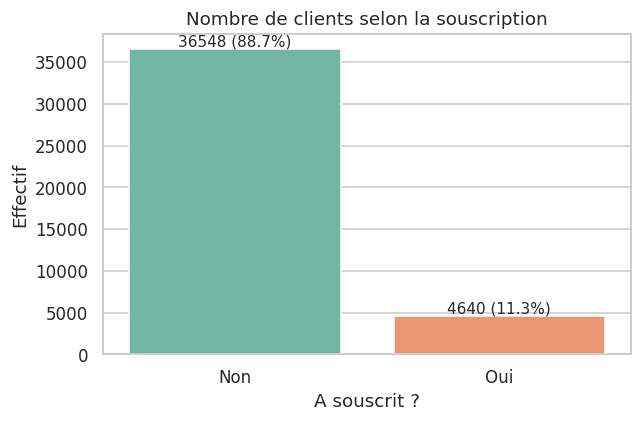

In [ ]:
# Diagramme en barres du nombre de clients par réponse
fig, ax = plt.subplots(figsize=(6, 4))
ordre = df["souscription"].value_counts().index
sns.countplot(data=df, x="souscription", order=ordre, hue="souscription", legend=False, ax=ax)
for patch in ax.patches:
    hauteur = int(patch.get_height())
    ax.annotate(f"{hauteur} ({hauteur / len(df):.1%})",
                (patch.get_x() + patch.get_width() / 2, hauteur),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Nombre de clients selon la souscription")
ax.set_xlabel("A souscrit ?")
ax.set_ylabel("Effectif")
plt.tight_layout()
plt.show()

**On observe :** seulement **11,3 %** des clients ont souscrit. Les classes sont **très déséquilibrées**.

C'est un point essentiel : un modèle qui répondrait toujours « non » aurait **88,7 % de bonnes réponses** sans rien apprendre. L'exactitude sera donc **trompeuse** ici. On utilisera surtout l'**AUC** et le **rappel** (la part des souscripteurs que le modèle retrouve).

### 4.2 Variables numériques selon la réponse

On compare la distribution de chaque variable chez les clients qui ont souscrit et chez les autres. Plus les deux courbes sont éloignées, plus la variable est utile.

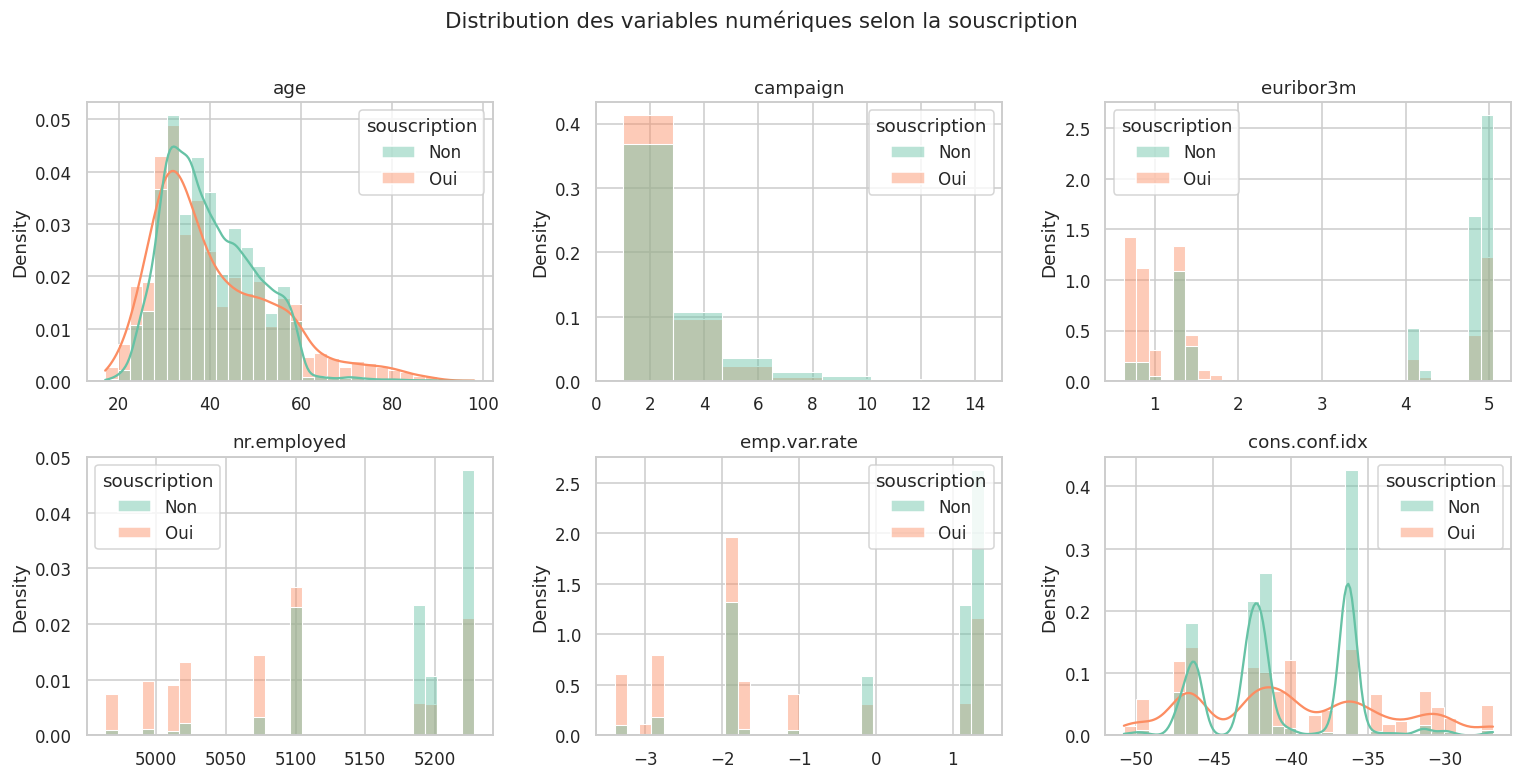

,age,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
souscription,,,,,,,,,
Non,38.0,2.0,999.0,0.0,1.1,93.92,-41.8,4.86,5195.8
Oui,37.0,2.0,999.0,0.0,-1.8,93.20,-40.4,1.27,5099.1


In [ ]:
# Distributions des principales variables numériques, par réponse
a_tracer = ["age", "campaign", "euribor3m", "nr.employed", "emp.var.rate", "cons.conf.idx"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, var in zip(axes.ravel(), a_tracer):
    sns.histplot(data=df, x=var, hue="souscription", stat="density", common_norm=False,
                 kde=var in ["age", "cons.conf.idx"], alpha=0.45, bins=30, ax=ax)
    ax.set_title(var)
    ax.set_xlabel("")
axes[0, 1].set_xlim(0, 15)
plt.suptitle("Distribution des variables numériques selon la souscription", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# Médianes par réponse, pour chiffrer les écarts
df.groupby("souscription")[variables_num].median().round(2)

**Ce qu'on observe :**

- Les **variables économiques** font la plus grande différence : les clients souscrivent beaucoup plus quand l'**Euribor** est bas (médiane de 1,27 chez les souscripteurs contre 4,86 chez les autres) et quand l'emploi baisse (`emp.var.rate` négatif).
- L'**âge** fait peu de différence en médiane, mais les plus jeunes et les plus âgés souscrivent un peu plus.
- **campaign** : les clients appelés de nombreuses fois souscrivent rarement.

### 4.3 Variables texte et taux de souscription

Pour chaque variable texte, on calcule le pourcentage de clients qui ont souscrit, pour chaque valeur. La ligne en pointillés est le taux moyen (11,3 %).

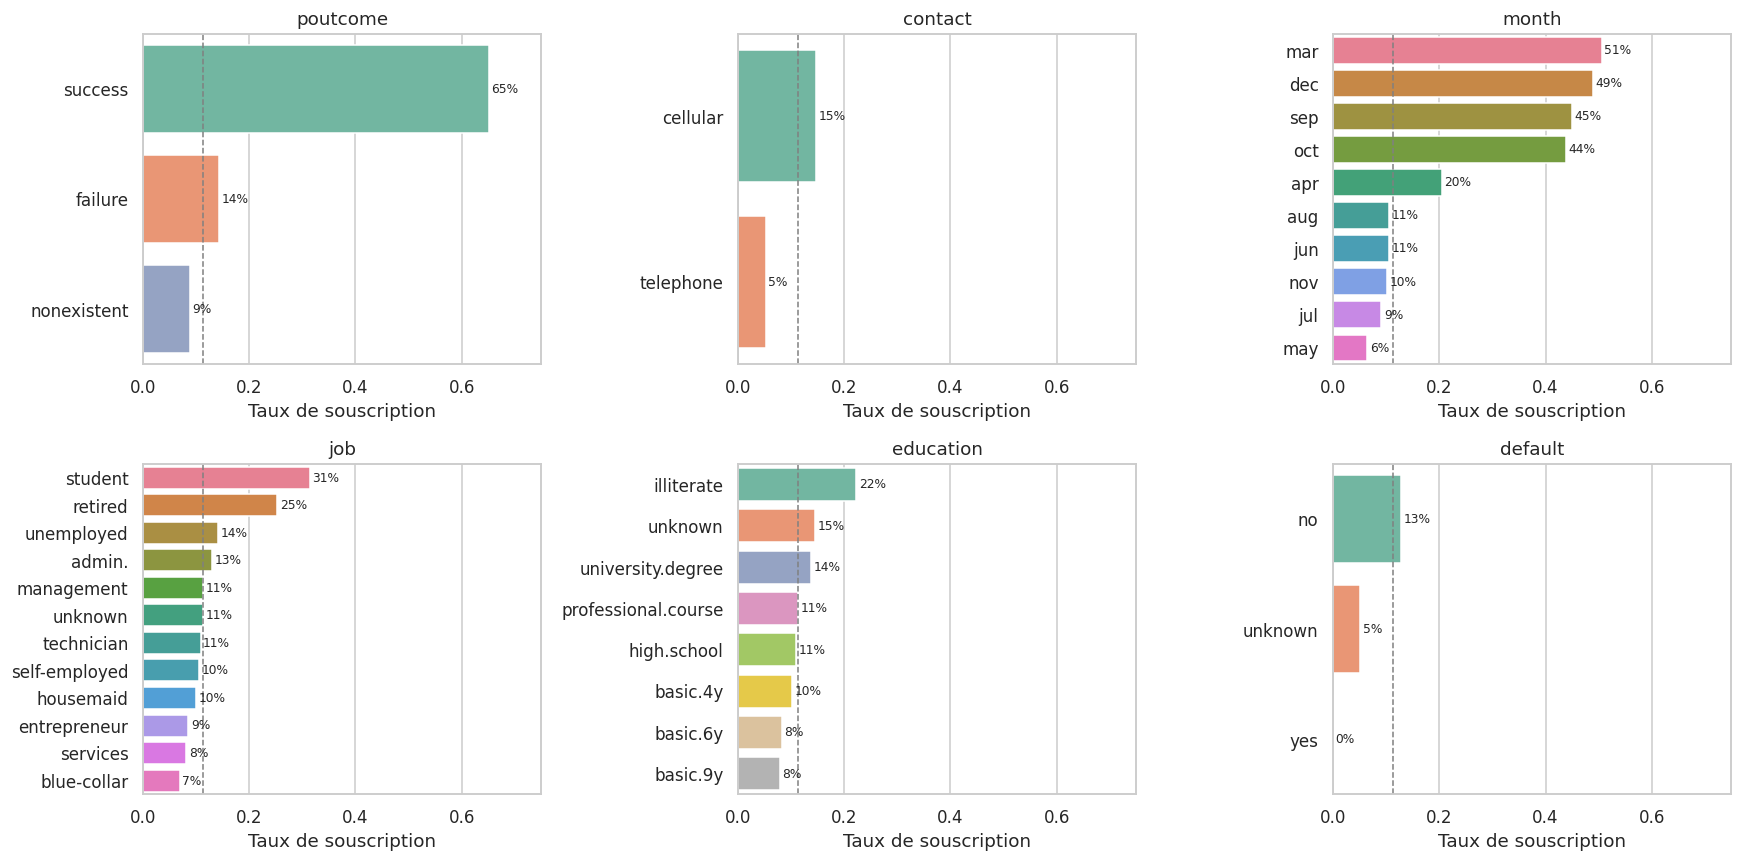

In [ ]:
# Taux de souscription par modalité
a_tracer_cat = ["poutcome", "contact", "month", "job", "education", "default"]
taux_global = (df["y"] == "yes").mean()

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, var in zip(axes.ravel(), a_tracer_cat):
    taux = df.groupby(var)["y"].apply(lambda s: (s == "yes").mean()).sort_values(ascending=False)
    sns.barplot(x=taux.values, y=taux.index, hue=taux.index, legend=False, ax=ax)
    ax.axvline(taux_global, color="grey", linestyle="--", linewidth=1)
    for i, t in enumerate(taux.values):
        ax.text(t + 0.005, i, f"{t:.0%}", va="center", fontsize=8)
    ax.set_title(var)
    ax.set_xlabel("Taux de souscription")
    ax.set_ylabel("")
    ax.set_xlim(0, 0.75)
plt.tight_layout()
plt.show()

**Ce qu'on observe :**

- **poutcome** est très parlant : quand la campagne précédente avait réussi, **65 %** des clients souscrivent à nouveau, contre 9 % pour les clients jamais contactés.
- **contact** : les clients appelés sur **portable** souscrivent presque trois fois plus (15 % contre 5 %).
- **month** : mars, septembre, octobre et décembre ont des taux très élevés (plus de 40 %), mais très peu d'appels y ont été passés. Mai, le mois le plus chargé, a le taux le plus bas (6 %).
- **job** : les **étudiants** (31 %) et les **retraités** (25 %) souscrivent le plus.
- **default** : les clients dont la situation de crédit est inconnue souscrivent moins (5 %).

### 4.4 Le cas de la variable duration

La variable `duration` est la durée de l'appel. On regarde son lien avec la souscription.

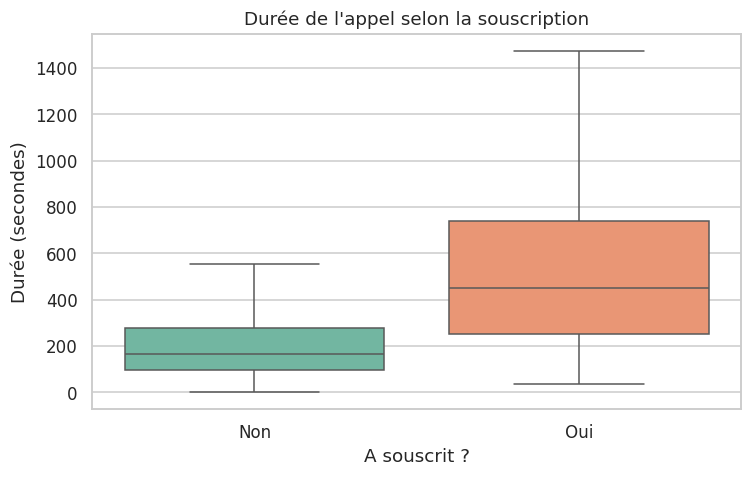

souscription
Non    163.5
Oui    449.0
Name: duration, dtype: float64


In [ ]:
# Durée de l'appel selon la réponse
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=df, x="souscription", y="duration", hue="souscription", legend=False,
            showfliers=False, ax=ax)
ax.set_title("Durée de l'appel selon la souscription")
ax.set_xlabel("A souscrit ?")
ax.set_ylabel("Durée (secondes)")
plt.tight_layout()
plt.show()

print(df.groupby("souscription")["duration"].median())

**Ce qu'on observe :** les appels qui aboutissent à une souscription durent beaucoup plus longtemps (médiane de 449 secondes contre 164).

**Mais on ne peut pas utiliser cette variable.** On ne connaît la durée de l'appel **qu'après l'avoir passé**, et à ce moment-là on connaît déjà la réponse du client. Or le but est de savoir **qui appeler avant l'appel**. Garder `duration` reviendrait à « tricher » : c'est ce qu'on appelle une **fuite de données**. Elle sera donc retirée (on le vérifiera dans la partie 8.2).

### 4.5 Relation entre deux variables

On place un échantillon de clients sur un graphique selon leur âge et le taux Euribor au moment de l'appel.

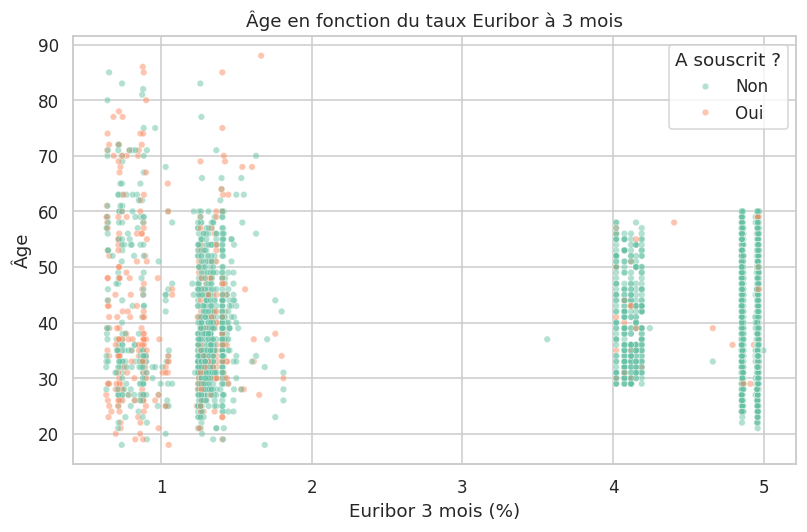

In [ ]:
# Nuage de points : âge et Euribor (échantillon de 4 000 clients pour la lisibilité)
echantillon = df.sample(4000, random_state=42)

fig, ax = plt.subplots(figsize=(7.5, 5))
sns.scatterplot(data=echantillon, x="euribor3m", y="age", hue="souscription",
                hue_order=["Non", "Oui"], s=18, alpha=0.5, ax=ax)
ax.set_title("Âge en fonction du taux Euribor à 3 mois")
ax.set_xlabel("Euribor 3 mois (%)")
ax.set_ylabel("Âge")
ax.legend(title="A souscrit ?")
plt.tight_layout()
plt.show()

**Ce qu'on observe :** les souscripteurs sont beaucoup plus nombreux quand l'Euribor est bas (à gauche), et parmi les clients jeunes ou âgés. Mais les deux groupes restent très mélangés : le modèle devra combiner toutes les variables.

### 4.6 Boîtes à moustaches et corrélations

Les boîtes à moustaches montrent la médiane et la dispersion. La matrice de corrélation montre si deux variables donnent la même information.

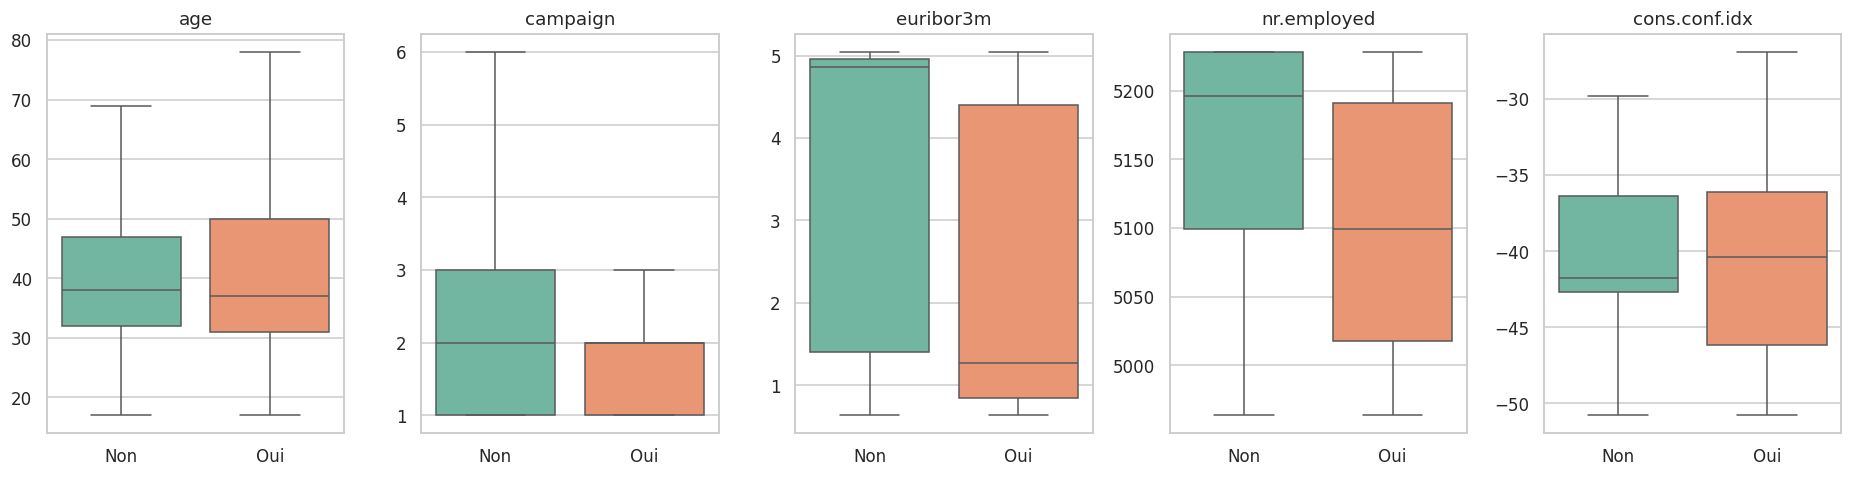

In [ ]:
# Boîtes à moustaches par réponse
fig, axes = plt.subplots(1, 5, figsize=(17, 4.5))
for ax, var in zip(axes, ["age", "campaign", "euribor3m", "nr.employed", "cons.conf.idx"]):
    sns.boxplot(data=df, x="souscription", y=var, hue="souscription", legend=False,
                showfliers=False, ax=ax)
    ax.set_title(var)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

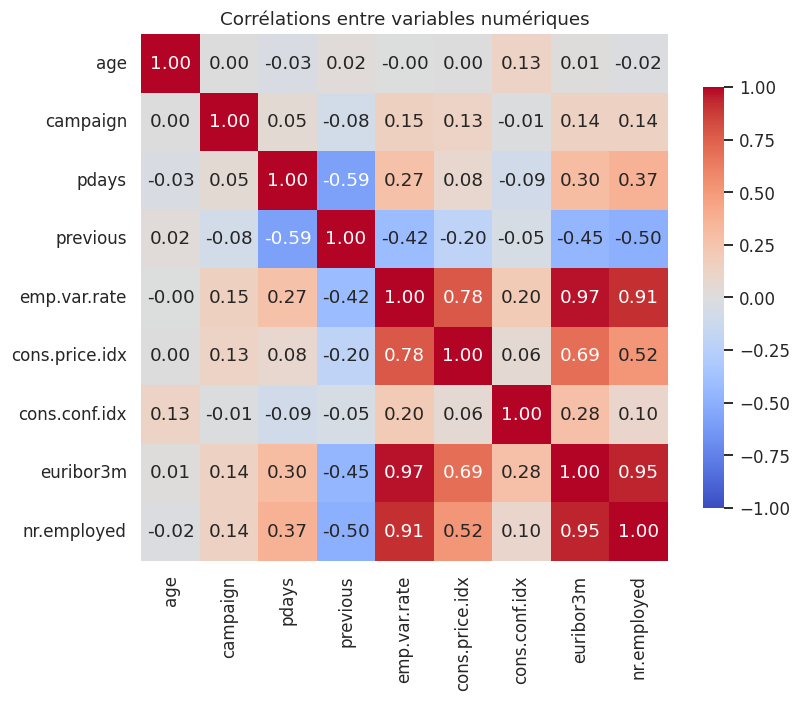

In [ ]:
# Matrice de corrélation des variables numériques
fig, ax = plt.subplots(figsize=(8, 6.5))
corr = df[variables_num].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Corrélations entre variables numériques")
plt.tight_layout()
plt.show()

**Ce qu'on observe :**

- Les boîtes à moustaches confirment que les souscriptions ont surtout lieu quand l'Euribor et le nombre de salariés sont bas.
- Les variables économiques sont **très corrélées entre elles** : `euribor3m`, `emp.var.rate` et `nr.employed` ont des corrélations supérieures à 0,9. Elles mesurent toutes la **conjoncture économique** et donnent presque la même information.

## 5. Préparation des données

Avant d'entraîner les modèles, on prépare les données :

1. **On supprime les 12 doublons.**
2. **On retire `duration`**, car on ne la connaît qu'après l'appel (fuite de données).
3. **On garde les `unknown` comme une catégorie à part** : ne pas connaître une information peut être une information en soi.
4. **On sépare les données** : 75 % pour l'entraînement, 25 % pour le test. Le test sert uniquement à la fin. Le découpage est **stratifié** pour garder 11,3 % de souscripteurs des deux côtés.
5. **On transforme le texte en nombres** : chaque valeur devient une colonne de 0 et de 1 (*one-hot encoding*).
6. **On met les nombres à la même échelle** (standardisation).

Les étapes 5 et 6 sont regroupées dans un **pipeline**, ce qui garantit qu'elles sont apprises sur l'entraînement uniquement.

In [ ]:
# 1) Suppression des doublons
df_propre = df.drop_duplicates().reset_index(drop=True)
print("Clients après suppression des doublons :", len(df_propre))

# 2) Séparation entrées / cible (1 = a souscrit, 0 = n'a pas souscrit), sans duration
X = df_propre.drop(columns=["y", "souscription", "duration"])
y = (df_propre["y"] == "yes").astype(int)
noms_classes = ["Non", "Oui"]   # dans l'ordre 0, 1

# 3) Découpage stratifié : 75 % entraînement, 25 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Entraînement :", X_train.shape[0], "| Test :", X_test.shape[0])
print("Taux de souscription dans l'entraînement :", round(y_train.mean(), 3))
print("Taux de souscription dans le test :", round(y_test.mean(), 3))

# 4) Prétraitement : standardisation des nombres, encodage du texte
preprocesseur = ColumnTransformer([
    ("num", StandardScaler(), variables_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), variables_cat),
])

Clients après suppression des doublons : 41176
Entraînement : 30882 | Test : 10294
Taux de souscription dans l'entraînement : 0.113
Taux de souscription dans le test : 0.113


## 6. Comparaison des modèles

On compare 6 modèles, du plus simple au plus complexe :

- une **référence** qui répond toujours « non » (elle ne regarde pas les données) ;
- la **régression logistique** ;
- les **k plus proches voisins** ;
- l'**arbre de décision** ;
- la **forêt aléatoire** ;
- le **gradient boosting**, qui construit des arbres les uns après les autres, chacun corrigeant les erreurs du précédent.

Comme il y a peu de souscripteurs, certains modèles reçoivent l'option `class_weight="balanced"` : elle donne **plus de poids aux souscripteurs** pendant l'apprentissage, pour que le modèle ne les ignore pas.

On utilise une **validation croisée à 5 plis** et on regarde trois indicateurs :

- l'**exactitude** : le pourcentage de bonnes réponses (trompeur ici) ;
- le **rappel** : la part des souscripteurs que le modèle retrouve ;
- l'**AUC** : entre 0,5 (hasard) et 1 (parfait), elle mesure si le modèle sait mettre un souscripteur au-dessus d'un non-souscripteur. **C'est l'indicateur principal ici.**

In [ ]:
# Modèles candidats, chacun précédé du même prétraitement
modeles = {
    "Référence (toujours non)": DummyClassifier(strategy="most_frequent"),
    "Régression logistique": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "K plus proches voisins (k=15)": KNeighborsClassifier(n_neighbors=15),
    "Arbre de décision": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                              class_weight="balanced", random_state=42, n_jobs=-1),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=42),
}

pipelines = {nom: Pipeline([("prep", preprocesseur), ("modele", m)])
             for nom, m in modeles.items()}

validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultats = []
for nom, pipe in pipelines.items():
    scores = cross_validate(pipe, X_train, y_train, cv=validation,
                            scoring=["accuracy", "recall", "roc_auc"])
    resultats.append({"Modèle": nom,
                      "Exactitude": scores["test_accuracy"].mean(),
                      "Rappel": scores["test_recall"].mean(),
                      "AUC moyenne": scores["test_roc_auc"].mean(),
                      "Écart-type AUC": scores["test_roc_auc"].std()})

tableau = pd.DataFrame(resultats).sort_values("AUC moyenne", ascending=False).reset_index(drop=True)
tableau.round(3)

,Modèle,Exactitude,Rappel,AUC moyenne,Écart-type AUC
0,Gradient boosting,0.900,0.250,0.798,0.013
1,Forêt aléatoire,0.866,0.585,0.790,0.011
2,Régression logistique,0.830,0.622,0.788,0.011
3,Arbre de décision,0.841,0.594,0.774,0.009
4,K plus proches voisins (k=15),0.897,0.263,0.754,0.008
5,Référence (toujours non),0.887,0.000,0.500,0.000


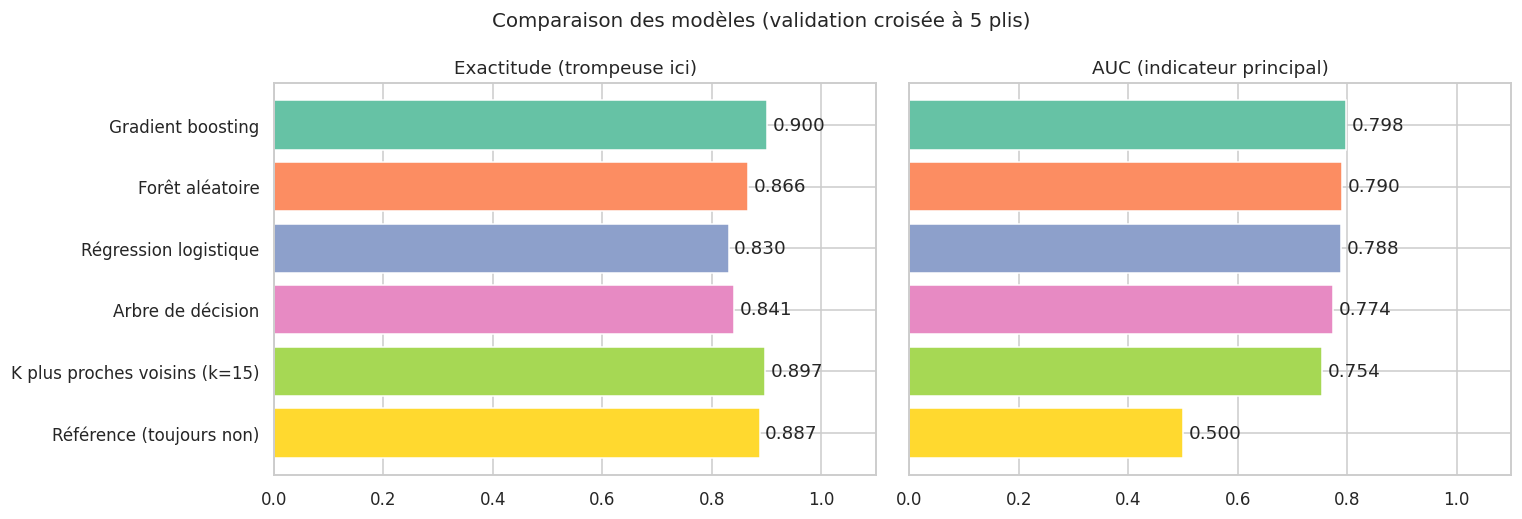

In [ ]:
# Graphique : exactitude et AUC côte à côte
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, col, titre in [(axes[0], "Exactitude", "Exactitude (trompeuse ici)"),
                       (axes[1], "AUC moyenne", "AUC (indicateur principal)")]:
    ax.barh(tableau["Modèle"], tableau[col], color=sns.color_palette("Set2", len(tableau)))
    for i, val in enumerate(tableau[col]):
        ax.text(val + 0.01, i, f"{val:.3f}", va="center")
    ax.set_xlim(0, 1.1)
    ax.set_title(titre)
axes[0].invert_yaxis()
plt.suptitle("Comparaison des modèles (validation croisée à 5 plis)", fontsize=13)
plt.tight_layout()
plt.show()

**Ce qu'on observe :**

- **Le piège de l'exactitude :** la référence a 88,7 % d'exactitude alors qu'elle ne retrouve **aucun** souscripteur (rappel de 0). Elle fait même mieux que la régression logistique sur cet indicateur. L'exactitude ne permet donc pas de choisir.
- **Avec l'AUC**, la référence tombe à 0,5 (le hasard) et les vrais modèles se situent autour de 0,76 à 0,80.
- **Le gradient boosting est le meilleur** (AUC d'environ 0,80), juste devant la forêt aléatoire et la régression logistique.
- Les modèles avec `class_weight="balanced"` retrouvent environ 60 % des souscripteurs. Le gradient boosting, sans cette option, n'en retrouve qu'environ 25 % avec le seuil par défaut. On verra en 7.2 comment corriger cela en changeant le seuil.

## 7. Évaluation finale sur le jeu de test

On entraîne le meilleur modèle (selon l'AUC) sur toutes les données d'entraînement, puis on le teste **une seule fois** sur les données de test.

In [ ]:
# Sélection du meilleur modèle selon l'AUC en validation croisée
meilleur_nom = tableau.iloc[0]["Modèle"]
meilleur_pipe = pipelines[meilleur_nom]
meilleur_pipe.fit(X_train, y_train)
y_proba = meilleur_pipe.predict_proba(X_test)[:, 1]
y_pred = meilleur_pipe.predict(X_test)

print("Meilleur modèle :", meilleur_nom)
print(f"AUC sur le jeu de test : {roc_auc_score(y_test, y_proba):.3f}")
print(f"Exactitude sur le jeu de test (seuil 0,5) : {accuracy_score(y_test, y_pred):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=noms_classes))

Meilleur modèle : Gradient boosting
AUC sur le jeu de test : 0.815
Exactitude sur le jeu de test (seuil 0,5) : 0.901

              precision    recall  f1-score   support

         Non       0.91      0.98      0.95      9134
         Oui       0.67      0.25      0.36      1160

    accuracy                           0.90     10294
   macro avg       0.79      0.62      0.65     10294
weighted avg       0.88      0.90      0.88     10294



### 7.1 Matrice de confusion

La matrice de confusion montre les bonnes réponses et les erreurs. Pour une campagne d'appels, il y a deux types d'erreurs :

- **faux positif** : le modèle prédit « oui » mais le client ne souscrit pas, donc **un appel inutile** (du temps perdu pour le conseiller) ;
- **faux négatif** : le modèle prédit « non » mais le client aurait souscrit, donc **une vente ratée**.

En général, une vente ratée coûte plus cher qu'un appel inutile.

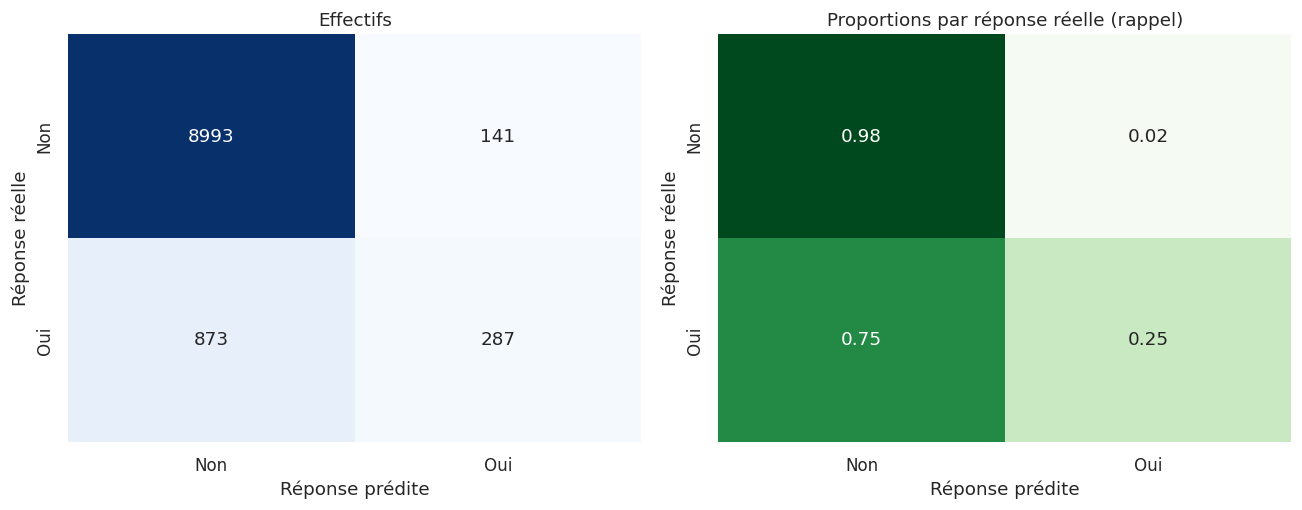

In [ ]:
# Matrice de confusion : valeurs absolues et proportions par ligne
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=noms_classes,
            yticklabels=noms_classes, cbar=False, ax=axes[0])
axes[0].set_title("Effectifs")
axes[0].set_xlabel("Réponse prédite")
axes[0].set_ylabel("Réponse réelle")

sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens", xticklabels=noms_classes,
            yticklabels=noms_classes, vmin=0, vmax=1, cbar=False, ax=axes[1])
axes[1].set_title("Proportions par réponse réelle (rappel)")
axes[1].set_xlabel("Réponse prédite")
axes[1].set_ylabel("Réponse réelle")
plt.tight_layout()
plt.show()

**Ce qu'on observe :** sur 10 294 clients du test, dont 1 160 souscripteurs, le modèle avec le seuil de 0,5 :

- retrouve **287 souscripteurs** sur 1 160, soit seulement **25 %** ;
- rate **873 souscripteurs** (ventes ratées) ;
- ne fait que **141 appels inutiles**.

Le modèle est donc **trop prudent** : il prédit « oui » seulement quand il est presque sûr. C'est pour cela que son exactitude est élevée (90 %) alors qu'il rate la plupart des souscripteurs.

### 7.2 Courbe ROC et choix du seuil

Par défaut, le modèle prédit « oui » si la probabilité dépasse 0,5. Avec seulement 11 % de souscripteurs, ce seuil est trop exigeant. En le **baissant**, on retrouve plus de souscripteurs, mais on passe aussi plus d'appels inutiles.

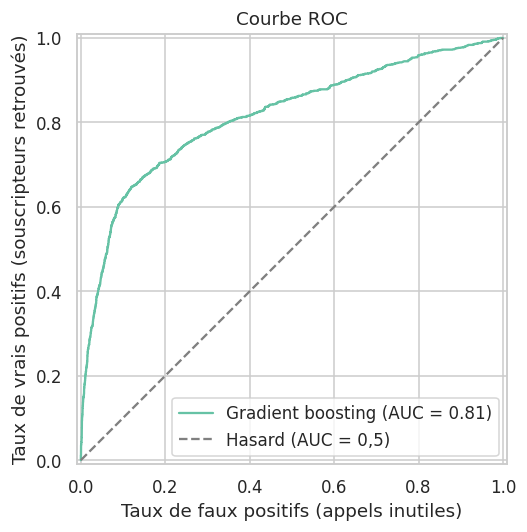

,Seuil,Clients à appeler,Souscripteurs retrouvés,Rappel,Appels inutiles,Ventes ratées
0,0.1,2163,781,0.673,1382,379
1,0.2,1488,694,0.598,794,466
2,0.3,1129,569,0.491,560,591
3,0.4,669,393,0.339,276,767
4,0.5,428,287,0.247,141,873


In [ ]:
# Courbe ROC du meilleur modèle sur le jeu de test
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, y_proba, name=meilleur_nom, ax=ax)
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Hasard (AUC = 0,5)")
ax.set_xlabel("Taux de faux positifs (appels inutiles)")
ax.set_ylabel("Taux de vrais positifs (souscripteurs retrouvés)")
ax.set_title("Courbe ROC")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Effet du seuil sur les deux types d'erreur
lignes = []
for seuil in [0.1, 0.2, 0.3, 0.4, 0.5]:
    pred = (y_proba >= seuil).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    lignes.append({"Seuil": seuil,
                   "Clients à appeler": vp + fp,
                   "Souscripteurs retrouvés": vp,
                   "Rappel": vp / (vp + fn),
                   "Appels inutiles": fp,
                   "Ventes ratées": fn})
pd.DataFrame(lignes).round(3)

**Ce qu'on observe :**

- L'AUC sur le test est d'environ **0,82** : le modèle classe bien mieux les clients que le hasard.
- En passant le seuil de 0,5 à **0,2**, le rappel passe de 25 % à **60 %** : on retrouve 694 souscripteurs au lieu de 287, en appelant 1 488 clients au lieu de 428.
- En contrepartie, il y a plus d'appels inutiles (794 au lieu de 141).

Le choix du seuil est une **décision de gestion** : il dépend du nombre d'appels que la banque peut passer et de ce que rapporte une souscription.

### 7.3 Courbe de gain : qui appeler en priorité ?

En marketing, on utilise souvent le modèle pour **classer les clients** du plus probable au moins probable, puis on appelle les premiers de la liste. La **courbe de gain** répond à la question : *si j'appelle les X % de clients les mieux classés, quelle part des souscripteurs vais-je toucher ?*

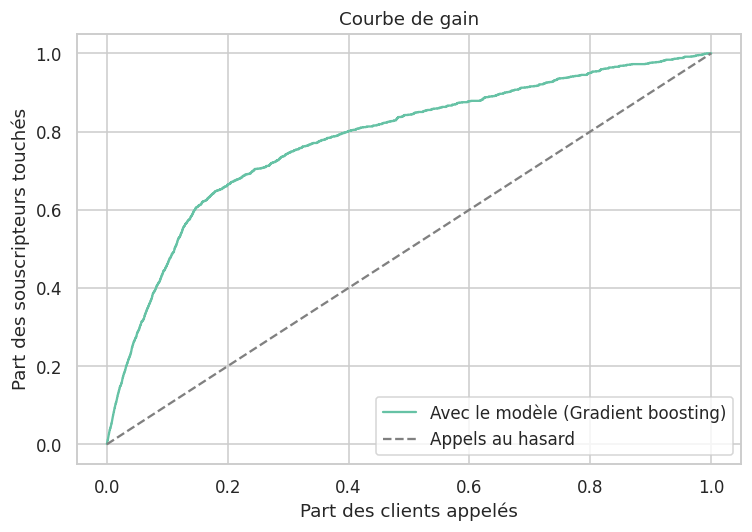

En appelant 10% des clients, on touche 46% des souscripteurs
En appelant 20% des clients, on touche 66% des souscripteurs
En appelant 30% des clients, on touche 74% des souscripteurs
En appelant 50% des clients, on touche 84% des souscripteurs


In [ ]:
# Courbe de gain : part des souscripteurs touchés selon la part de clients appelés
ordre_score = np.argsort(-y_proba)
souscripteurs_tries = y_test.values[ordre_score]
part_clients = np.arange(1, len(y_test) + 1) / len(y_test)
part_souscripteurs = np.cumsum(souscripteurs_tries) / souscripteurs_tries.sum()

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(part_clients, part_souscripteurs, label=f"Avec le modèle ({meilleur_nom})")
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Appels au hasard")
ax.set_xlabel("Part des clients appelés")
ax.set_ylabel("Part des souscripteurs touchés")
ax.set_title("Courbe de gain")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

for p in [0.1, 0.2, 0.3, 0.5]:
    k = int(p * len(y_test))
    print(f"En appelant {p:.0%} des clients, on touche {part_souscripteurs[k - 1]:.0%} des souscripteurs")

**Ce qu'on observe :**

- En appelant seulement les **20 % de clients les mieux classés**, on touche **66 % des souscripteurs**. Au hasard, on n'en toucherait que 20 %.
- En appelant **la moitié** des clients, on touche 84 % des souscripteurs.

Pour la banque, cela veut dire qu'on peut **réduire fortement le nombre d'appels** tout en gardant la majorité des ventes. C'est l'usage le plus concret du modèle.

### 7.4 Courbe d'apprentissage

La courbe d'apprentissage montre si le modèle s'améliore quand on lui donne plus de données.

- Si les deux courbes sont basses : le modèle est trop simple (**sous-apprentissage**).
- S'il y a un grand écart entre les deux courbes : le modèle apprend par cœur (**surapprentissage**).

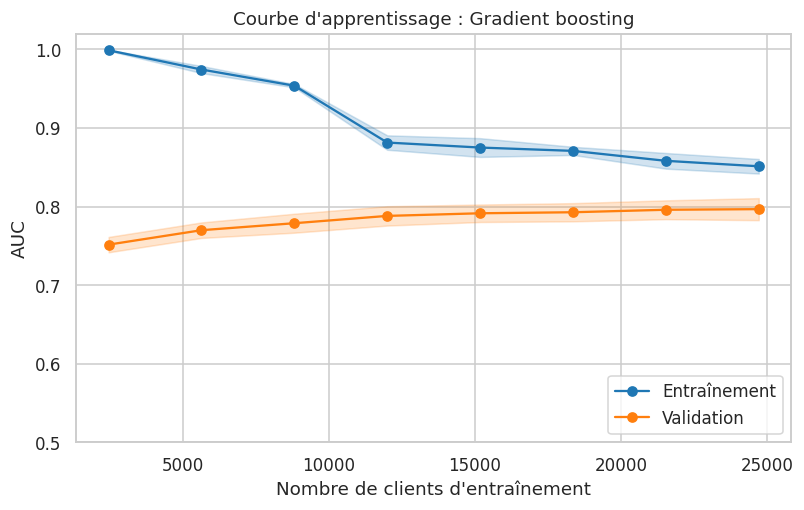

In [ ]:
# Courbe d'apprentissage du meilleur modèle (AUC)
tailles, scores_train, scores_val = learning_curve(
    meilleur_pipe, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 8), cv=validation, scoring="roc_auc", n_jobs=-1
)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
for scores, label, couleur in [(scores_train, "Entraînement", "tab:blue"),
                               (scores_val, "Validation", "tab:orange")]:
    moyenne, ecart = scores.mean(axis=1), scores.std(axis=1)
    ax.plot(tailles, moyenne, "o-", color=couleur, label=label)
    ax.fill_between(tailles, moyenne - ecart, moyenne + ecart, alpha=0.2, color=couleur)
ax.set_xlabel("Nombre de clients d'entraînement")
ax.set_ylabel("AUC")
ax.set_title(f"Courbe d'apprentissage : {meilleur_nom}")
ax.set_ylim(0.5, 1.02)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Ce qu'on observe :**

- Avec peu de données, le modèle apprend presque par cœur (AUC de 1 en entraînement), mais il généralise moins bien.
- Quand le nombre de clients augmente, les deux courbes se rapprochent : le score de validation monte de 0,75 à 0,80.
- À la fin, la courbe de validation est presque plate : **ajouter des clients n'améliorerait plus beaucoup le modèle**. Pour progresser, il faudrait plutôt de **nouvelles informations** sur les clients (revenus, épargne, etc.).

## 8. Interprétation du modèle

### 8.1 Importance des variables

Pour savoir quelles variables comptent le plus, on utilise l'**importance par permutation** : on mélange au hasard les valeurs d'une variable et on regarde de combien l'AUC baisse. Plus elle baisse, plus la variable est importante. Cette méthode marche avec n'importe quel modèle.

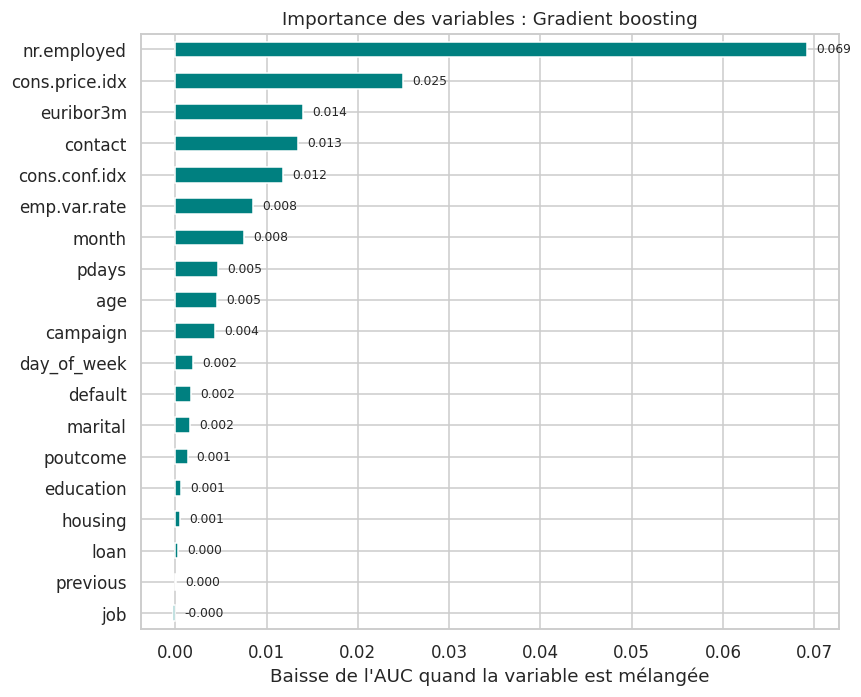

In [35]:
# Importance par permutation sur le jeu de test (baisse de l'AUC)
resultat = permutation_importance(meilleur_pipe, X_test, y_test, scoring="roc_auc",
                                  n_repeats=5, random_state=42, n_jobs=-1)
importances = pd.Series(resultat.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 6.5))
importances.plot.barh(ax=ax, color="teal")
for i, val in enumerate(importances):
    ax.text(max(val, 0) + 0.001, i, f"{val:.3f}", va="center", fontsize=8)
ax.set_xlabel("Baisse de l'AUC quand la variable est mélangée")
ax.set_title(f"Importance des variables : {meilleur_nom}")
plt.tight_layout()
plt.show()

**Ce qu'on observe :**

- **nr.employed** (le nombre de salariés dans l'économie) est de loin la variable la plus importante, suivie des autres **indicateurs économiques** (`cons.price.idx`, `euribor3m`, `cons.conf.idx`).
- **contact** (portable ou fixe) et **month** comptent aussi.
- Les informations personnelles (job, education, loan…) comptent très peu.

Conclusion : le **contexte économique au moment de l'appel** compte plus que le profil du client. Attention : comme les variables économiques sont très corrélées, leur importance se partage entre elles. Et `poutcome` paraît peu importante parce que `pdays` contient presque la même information.

### 8.2 Pourquoi a-t-on retiré duration ?

On entraîne le même modèle **avec** la variable `duration` pour voir ce qui se passe.

In [36]:
# Même modèle, mais en gardant duration
X_avec = df_propre.drop(columns=["y", "souscription"])
Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    X_avec, y, test_size=0.25, random_state=42, stratify=y
)
prep_avec = ColumnTransformer([
    ("num", StandardScaler(), variables_num + ["duration"]),
    ("cat", OneHotEncoder(handle_unknown="ignore"), variables_cat),
])
modele_avec = Pipeline([("prep", prep_avec),
                        ("modele", HistGradientBoostingClassifier(random_state=42))])
modele_avec.fit(Xa_train, ya_train)
auc_avec = roc_auc_score(ya_test, modele_avec.predict_proba(Xa_test)[:, 1])

print(f"AUC sans duration : {roc_auc_score(y_test, y_proba):.3f}")
print(f"AUC avec duration : {auc_avec:.3f}")

AUC sans duration : 0.815
AUC avec duration : 0.950


**Ce qu'on observe :** avec `duration`, l'AUC passe de 0,82 à **0,95**. Le modèle paraît bien meilleur, mais c'est **un faux progrès** : en pratique, on ne connaît pas la durée de l'appel avant de le passer. Un modèle avec `duration` serait donc **inutilisable** pour choisir qui appeler. Cet exemple montre qu'un très bon score n'est pas toujours un bon modèle : il faut toujours se demander si les variables seront **disponibles au moment de la prédiction**.

### 8.3 Frontières de décision

Pour voir comment un modèle sépare les classes, on utilise seulement deux variables : l'âge et l'Euribor. Chaque zone de couleur correspond à une prédiction.

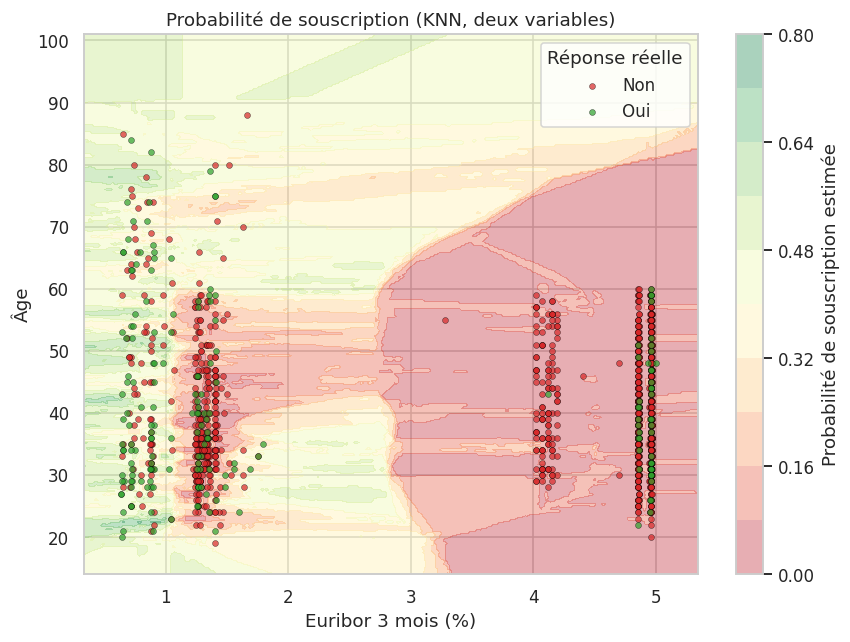

AUC du KNN à deux variables sur le test : 0.777


In [37]:
# Frontières de décision avec deux variables : euribor3m et age
deux = ["euribor3m", "age"]
modele_2d = Pipeline([("scaler", StandardScaler()),
                      ("knn", KNeighborsClassifier(n_neighbors=50))])
modele_2d.fit(X_train[deux], y_train)

x_min, x_max = X_train[deux[0]].min() - 0.3, X_train[deux[0]].max() + 0.3
y_min, y_max = X_train[deux[1]].min() - 3, X_train[deux[1]].max() + 3
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grille = pd.DataFrame({deux[0]: xx.ravel(), deux[1]: yy.ravel()})
zz = modele_2d.predict_proba(grille)[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 6))
fond = ax.contourf(xx, yy, zz, levels=10, cmap="RdYlGn", alpha=0.35)
fig.colorbar(fond, ax=ax, label="Probabilité de souscription estimée")
points = X_test.assign(y=y_test.values).sample(1500, random_state=42)
for valeur, nom, couleur in [(0, "Non", "tab:red"), (1, "Oui", "tab:green")]:
    masque = points["y"] == valeur
    ax.scatter(points.loc[masque, deux[0]], points.loc[masque, deux[1]],
               label=nom, s=15, color=couleur, edgecolor="k", linewidth=0.3, alpha=0.7)
ax.set_xlabel("Euribor 3 mois (%)")
ax.set_ylabel("Âge")
ax.set_title("Probabilité de souscription (KNN, deux variables)")
ax.legend(title="Réponse réelle")
plt.tight_layout()
plt.show()

auc_2d = roc_auc_score(y_test, modele_2d.predict_proba(X_test[deux])[:, 1])
print(f"AUC du KNN à deux variables sur le test : {auc_2d:.3f}")

## 9. Prédire pour un nouveau client

On utilise le modèle pour estimer la probabilité qu'un nouveau client (inventé) souscrive. Le pipeline applique automatiquement la même préparation.

In [38]:
# Nouveau client fictif
nouveau = pd.DataFrame([{
    "age": 30, "job": "student", "marital": "single", "education": "university.degree",
    "default": "no", "housing": "no", "loan": "no", "contact": "cellular",
    "month": "oct", "day_of_week": "tue", "campaign": 1, "pdays": 999, "previous": 0,
    "poutcome": "nonexistent", "emp.var.rate": -1.8, "cons.price.idx": 92.9,
    "cons.conf.idx": -46.2, "euribor3m": 1.3, "nr.employed": 5099.1
}])
proba = meilleur_pipe.predict_proba(nouveau)[0, 1]
print(f"Probabilité de souscription estimée : {proba:.2f}")

# Même client, mais appelé en mai dans une conjoncture où l'Euribor est élevé
nouveau_2 = nouveau.assign(month="may", **{"emp.var.rate": 1.1, "cons.price.idx": 93.99,
                                           "cons.conf.idx": -36.4, "euribor3m": 4.86,
                                           "nr.employed": 5191.0})
print(f"Même client, en mai avec un Euribor élevé : {meilleur_pipe.predict_proba(nouveau_2)[0, 1]:.2f}")

Probabilité de souscription estimée : 0.44
Même client, en mai avec un Euribor élevé : 0.05


**Ce qu'on observe :** pour un étudiant appelé sur son portable en octobre, avec un Euribor bas, la probabilité de souscription est de **0,44**, soit environ quatre fois le taux moyen. Le même client appelé en mai, avec un Euribor élevé, n'a plus que **0,05**. Cela montre encore le poids du **moment de l'appel** et du **contexte économique**.

## 10. Conclusion

**Ce qu'il faut retenir :**

1. C'est un problème d'**apprentissage supervisé** de **classification binaire**.
2. Les classes sont **très déséquilibrées** (11 % de souscripteurs) : l'exactitude est trompeuse, il faut regarder l'**AUC** et le **rappel**.
3. Il faut retirer **duration**, qu'on ne connaît qu'après l'appel (fuite de données).
4. Le **gradient boosting** est le meilleur modèle (AUC d'environ 0,82 sur le test).
5. En baissant le seuil ou en appelant en priorité les clients les mieux classés, la banque peut toucher **66 % des souscripteurs en appelant seulement 20 % des clients**.
6. Le **contexte économique** (emploi, Euribor) et le **moment de l'appel** comptent plus que le profil du client.